In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel(r"C:\Users\Lenovo\OneDrive\Desktop\intershala\Machine_learning\course_Assignments\final_Project\property_prices.xlsx")

print("First 5 records:")
df.head()

First 5 records:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
0,-117.91,32.74,18,4512,878,1039,257,13.5444,NEAR BAY,509430
1,-120.08,32.78,14,4311,1082,417,113,11.1663,ISLAND,431682
2,-122.10,38.04,52,606,182,1507,368,6.0934,INLAND,220512
3,-114.73,35.66,6,6724,1138,3017,791,12.3962,NEAR OCEAN,485828
4,-123.05,41.17,6,9544,1991,3162,847,11.0117,NEAR BAY,452487


In [5]:
print("\nLast 5 Records")
print(df.tail())

print("\nDataset Information")
print(df.info())

print("\nShape of Dataset")
print(df.shape)

print("\nColumn Names")
print(df.columns)

print("\nData Types")
print(df.dtypes)

print("\nSummary Statistics")
print(df.describe())


print("\nMissing Values")
print(df.isnull().sum())

print("\nDuplicate Records")
print(df.duplicated().sum())

print("\nUnique Values")
print(df.nunique())

print("\nCorrelation Matrix")
print(df.corr(numeric_only=True))


Last 5 Records
    longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
45    -122.38     38.75                  25         3351             915   
46    -122.20     39.89                  39         5779            1404   
47    -123.45     37.35                  41         5991            1010   
48    -124.06     34.80                  31         1693             408   
49    -121.86     38.67                   1         2246             686   

    population  households  median_income ocean_proximity  median_house_value  
45        2665         828        12.7553       <1H OCEAN              457462  
46        3822         949         8.4008          INLAND              334402  
47        2124         528         4.5326          INLAND              182434  
48        4915        1902        10.9008      NEAR OCEAN              402015  
49        1992         788        14.4325          ISLAND              548219  

Dataset Information
<class 'pandas.core.frame.

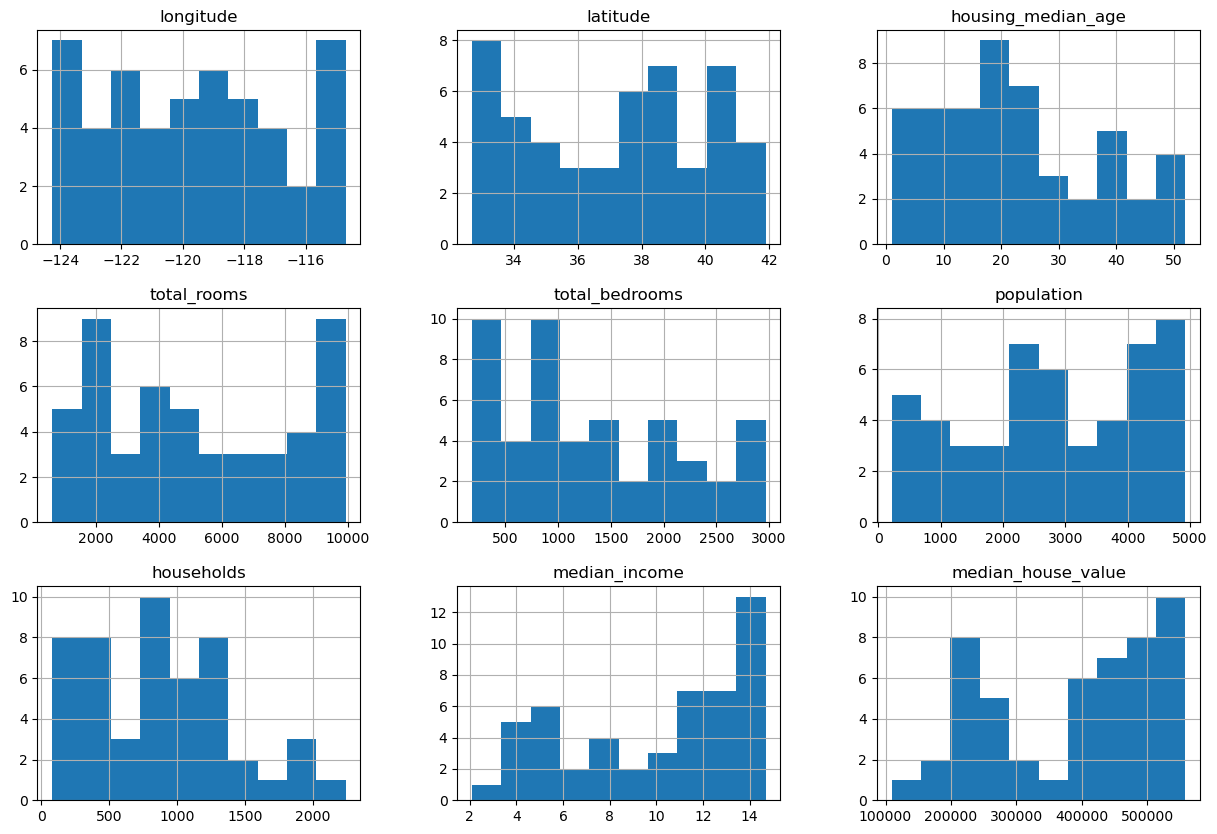

In [6]:
#visulization EDA

#histogram
df.hist(figsize=(15,10))
plt.show()

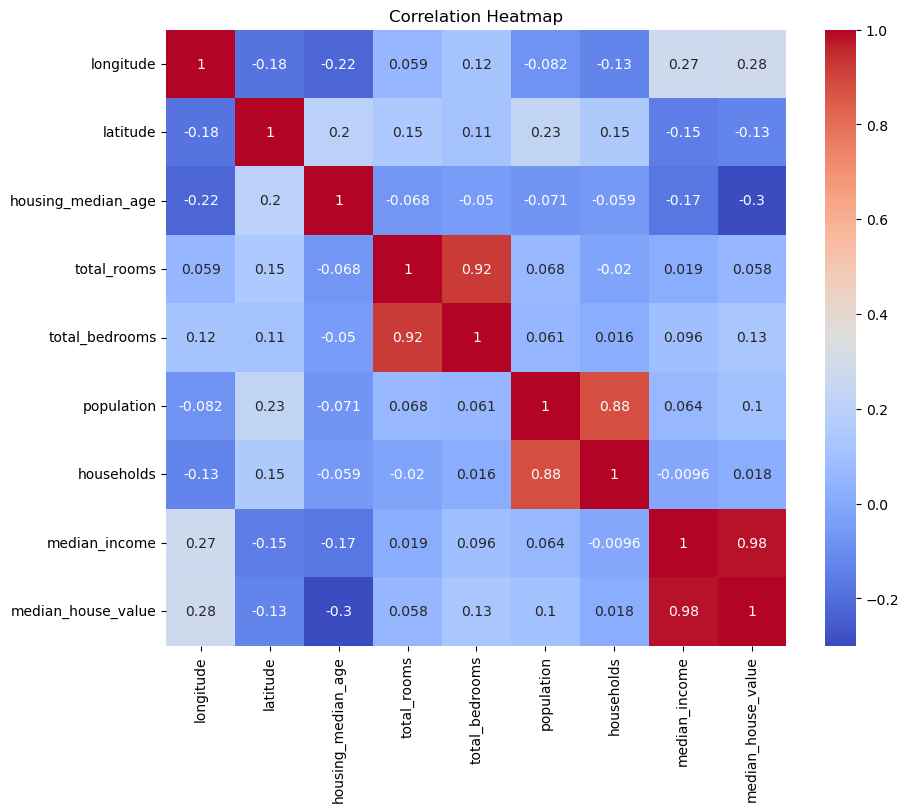

In [7]:
#Correlationn Heatmap

plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

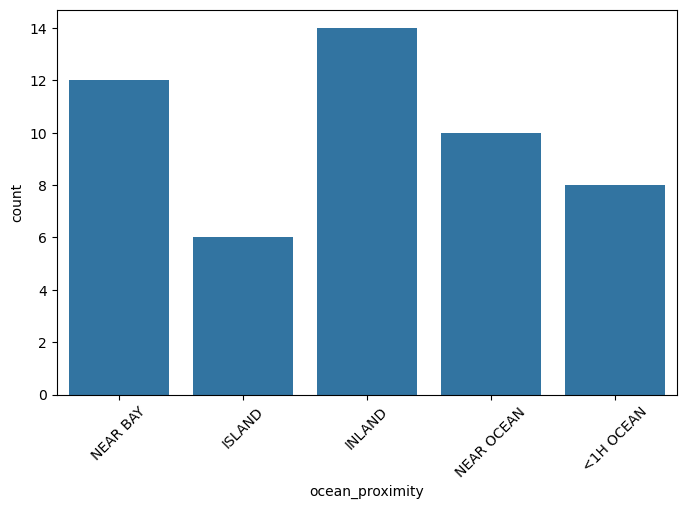

In [8]:
#count Plot(ocean Proximity)
plt.figure(figsize=(8,5))
sns.countplot(x="ocean_proximity", data=df)
plt.xticks(rotation=45)
plt.show()

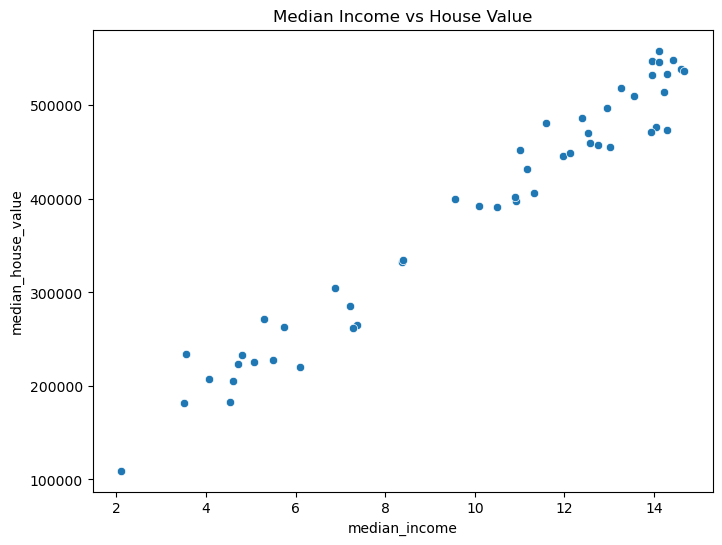

In [10]:
#scatter PLot

plt.figure(figsize=(8,6))
sns.scatterplot(x="median_income",
                y="median_house_value",
                data=df)

plt.title("Median Income vs House Value")
plt.show()

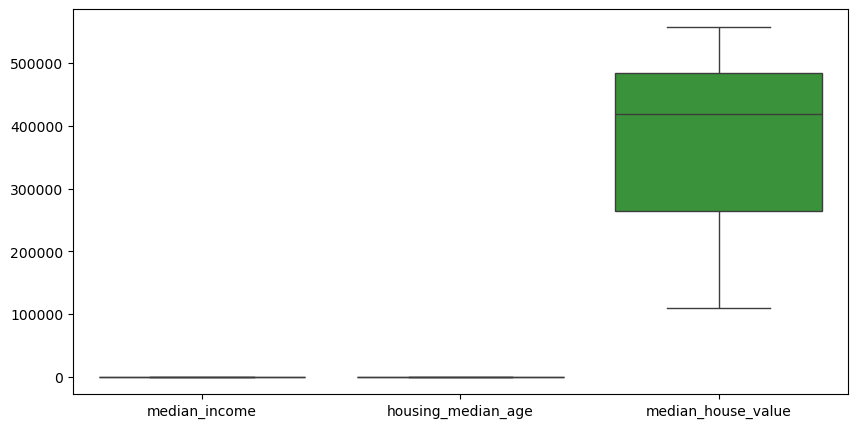

In [11]:
#Box Plot

plt.figure(figsize=(10,5))
sns.boxplot(data=df[["median_income",
                     "housing_median_age",
                     "median_house_value"]])
plt.show()

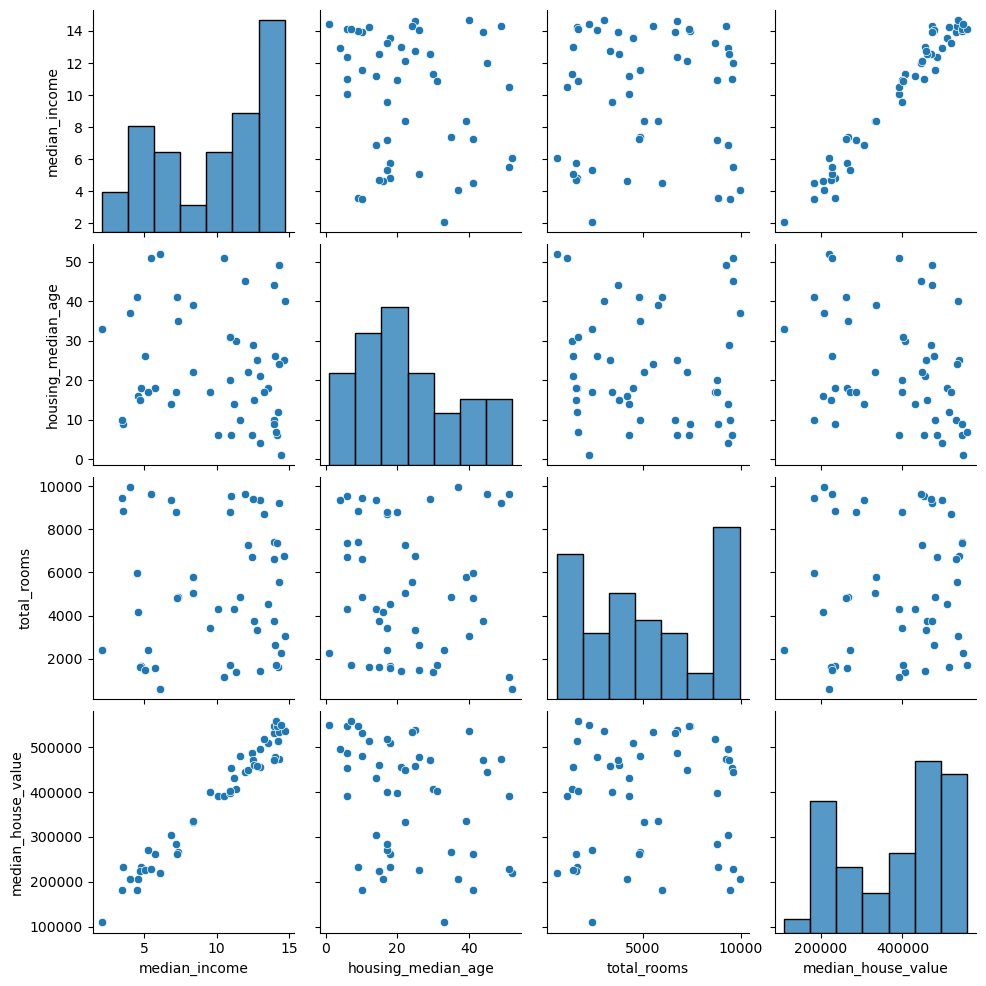

In [12]:
#Pair Plot

sns.pairplot(df[["median_income",
                 "housing_median_age",
                 "total_rooms",
                 "median_house_value"]])
plt.show()

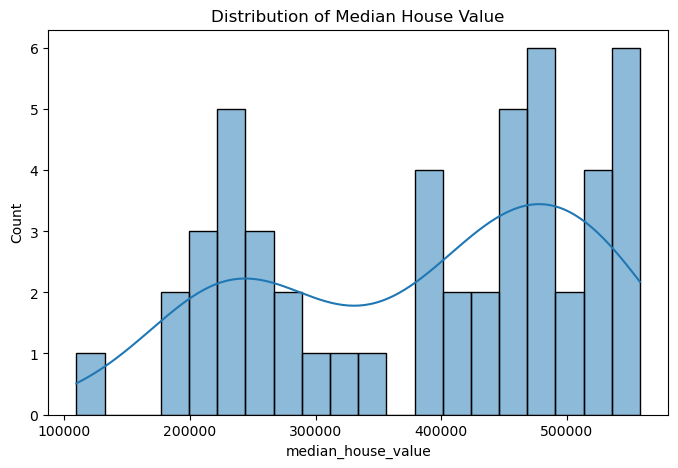

In [16]:
#Distribution
plt.figure(figsize=(8,5))
sns.histplot(df["median_house_value"], bins=20, kde=True)
plt.title("Distribution of Median House Value")
plt.show()

In [19]:
# Check missing values
print(df.isnull().sum())
df["total_bedrooms"].fillna(df["total_bedrooms"].median(), inplace=True)
print(df.isnull().sum())

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
median_house_value    0
dtype: int64
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
median_house_value    0
dtype: int64


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7856\1141598616.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["total_bedrooms"].fillna(df["total_bedrooms"].median(), inplace=True)


In [20]:
#Encoding

from sklearn.preprocessing import LabelEncoder 
le=LabelEncoder()

df["ocean_proximity"]=le.fit_transform(df["ocean_proximity"])

print(df.head())

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -117.91     32.74                  18         4512             878   
1    -120.08     32.78                  14         4311            1082   
2    -122.10     38.04                  52          606             182   
3    -114.73     35.66                   6         6724            1138   
4    -123.05     41.17                   6         9544            1991   

   population  households  median_income  ocean_proximity  median_house_value  
0        1039         257        13.5444                3              509430  
1         417         113        11.1663                2              431682  
2        1507         368         6.0934                1              220512  
3        3017         791        12.3962                4              485828  
4        3162         847        11.0117                3              452487  


In [21]:
X=df.drop("median_house_value",axis=1)
y=df["median_house_value"]

print(X.head())
print(y.head())

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -117.91     32.74                  18         4512             878   
1    -120.08     32.78                  14         4311            1082   
2    -122.10     38.04                  52          606             182   
3    -114.73     35.66                   6         6724            1138   
4    -123.05     41.17                   6         9544            1991   

   population  households  median_income  ocean_proximity  
0        1039         257        13.5444                3  
1         417         113        11.1663                2  
2        1507         368         6.0934                1  
3        3017         791        12.3962                4  
4        3162         847        11.0117                3  
0    509430
1    431682
2    220512
3    485828
4    452487
Name: median_house_value, dtype: int64


In [22]:
#split dataset

from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:",X_train.shape)
print("Training Data:",X_test.shape)

Training Data: (40, 9)
Training Data: (10, 9)


In [23]:
#simple Linear Regression

from sklearn.linear_model import LinearRegression

X_simple=df[["median_income"]]
y=df["median_house_value"]

X_train,X_test,y_train,y_test=train_test_split(
   X_simple,
    y,
    test_size=0.2,
    random_state=42
    )

simple_model=LinearRegression()

simple_model.fit(X_train,y_train)

y_pred_simple=simple_model.predict(X_test)

print(y_pred_simple)

[491848.88209509 469870.71375015 519435.58717535 475671.41289394
 284521.92830648 415270.53382505 484022.33518743 239549.4107447
 232973.54798708 213737.76520029]


In [24]:
from sklearn.metrics import mean_squared_error,r2_score

import numpy as np

mse=mean_squared_error(y_test,y_pred_simple)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred_simple)

print("MSE:",mse)
print("RMSE:",rmse)
print("R2 Score:",r2)

MSE: 578961111.1880826
RMSE: 24061.61073552813
R2 Score: 0.9567326437553557


In [26]:
result=pd.DataFrame({
    "Actual":y_test.values,
    "Predicted":y_pred_simple
})

print(result.head(10))

   Actual      Predicted
0  518319  491848.882095
1  459925  469870.713750
2  558193  519435.587175
3  457462  475671.412894
4  304503  284521.928306
5  402015  415270.533825
6  454878  484022.335187
7  227925  239549.410745
8  271740  232973.547987
9  223433  213737.765200


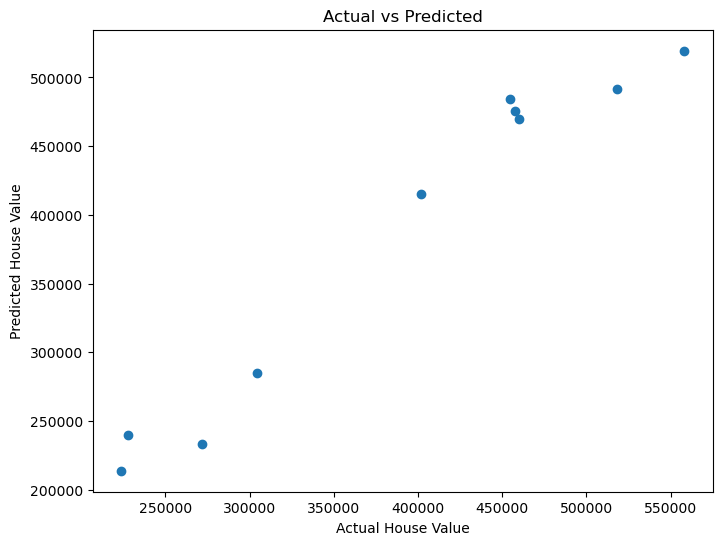

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(y_test,y_pred_simple)
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted")
plt.show()